In [16]:
import os
import random
import shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [18]:
dataset_path = r"C:\Users\divye\OneDrive\Desktop\College Sem_3\Projects\solar-panel-defect-detection\data\dataset_orignal"

print("Dataset exists:", os.path.exists(dataset_path))

Dataset exists: True


In [19]:
classes = sorted([
    folder for folder in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, folder))
])

print("Classes:")

for i, cls in enumerate(classes):
    print(i, "->", cls)

print("\nNumber of classes:", len(classes))

Classes:
0 -> Bird-drop
1 -> Clean
2 -> Dusty
3 -> Electrical-damage
4 -> Physical-Damage
5 -> Snow-Covered

Number of classes: 6


In [20]:
image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)

class_counts = {}

for cls in classes:

    class_path = os.path.join(dataset_path, cls)

    count = 0

    for file in os.listdir(class_path):

        if file.lower().endswith(image_extensions):
            count += 1

    class_counts[cls] = count


print("Image count per class:\n")

for cls, count in class_counts.items():
    print(f"{cls}: {count}")

Image count per class:

Bird-drop: 191
Clean: 193
Dusty: 190
Electrical-damage: 103
Physical-Damage: 69
Snow-Covered: 123


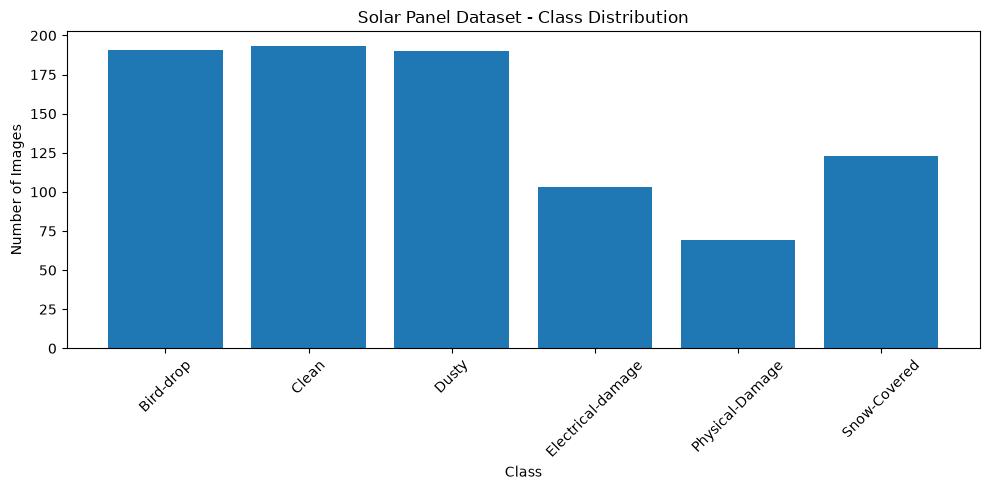

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Solar Panel Dataset - Class Distribution")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

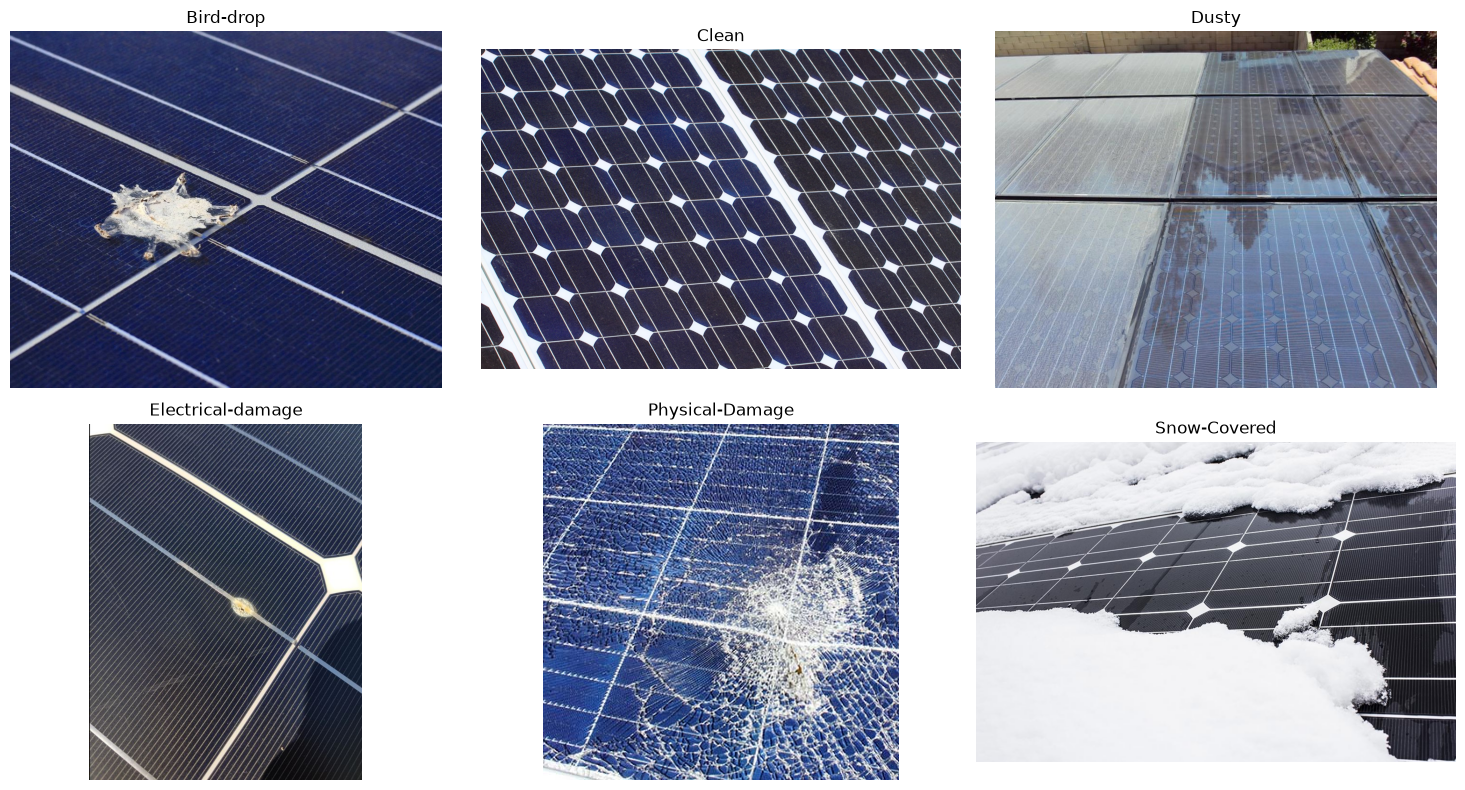

In [22]:
plt.figure(figsize=(15, 8))

plot_index = 1

for cls in classes:

    class_path = os.path.join(dataset_path, cls)

    image_files = [
        file for file in os.listdir(class_path)
        if file.lower().endswith(image_extensions)
    ]

    if len(image_files) == 0:
        continue

    image_file = random.choice(image_files)

    image_path = os.path.join(
        class_path,
        image_file
    )

    image = plt.imread(image_path)

    plt.subplot(2, 3, plot_index)

    plt.imshow(image)

    plt.title(cls)

    plt.axis("off")

    plot_index += 1

plt.tight_layout()
plt.show()

In [23]:
project_data_path = os.path.dirname(dataset_path)

train_path = os.path.join(project_data_path, "train")
val_path = os.path.join(project_data_path, "val")
test_path = os.path.join(project_data_path, "test")

print("Train path:", train_path)
print("Validation path:", val_path)
print("Test path:", test_path)

Train path: C:\Users\divye\OneDrive\Desktop\College Sem_3\Projects\solar-panel-defect-detection\data\train
Validation path: C:\Users\divye\OneDrive\Desktop\College Sem_3\Projects\solar-panel-defect-detection\data\val
Test path: C:\Users\divye\OneDrive\Desktop\College Sem_3\Projects\solar-panel-defect-detection\data\test


In [26]:
random.seed(42)

# Create train, validation and test folders
for main_folder in [train_path, val_path, test_path]:

    os.makedirs(main_folder, exist_ok=True)

    for cls in classes:
        os.makedirs(
            os.path.join(main_folder, cls),
            exist_ok=True
        )


for cls in classes:

    source_folder = os.path.join(
        dataset_path,
        cls
    )

    # Get image files
    files = [
        file for file in os.listdir(source_folder)
        if file.lower().endswith(image_extensions)
    ]

    # Shuffle
    random.shuffle(files)

    total = len(files)

    train_end = int(total * 0.70)
    val_end = int(total * 0.85)

    train_files = files[:train_end]

    val_files = files[train_end:val_end]

    test_files = files[val_end:]

    # Copy training images
    for file in train_files:

        shutil.copy2(
            os.path.join(source_folder, file),
            os.path.join(train_path, cls, file)
        )

    # Copy validation images
    for file in val_files:

        shutil.copy2(
            os.path.join(source_folder, file),
            os.path.join(val_path, cls, file)
        )

    # Copy testing images
    for file in test_files:

        shutil.copy2(
            os.path.join(source_folder, file),
            os.path.join(test_path, cls, file)
        )

    print(
        f"{cls}: "
        f"{len(train_files)} train | "
        f"{len(val_files)} validation | "
        f"{len(test_files)} test"
    )

print("\nDataset splitting completed.")

Bird-drop: 133 train | 29 validation | 29 test
Clean: 135 train | 29 validation | 29 test
Dusty: 133 train | 28 validation | 29 test
Electrical-damage: 72 train | 15 validation | 16 test
Physical-Damage: 48 train | 10 validation | 11 test
Snow-Covered: 86 train | 18 validation | 19 test

Dataset splitting completed.


In [27]:

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

SEED = 42

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: (224, 224)
Batch size: 32


In [28]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    shuffle=True
)

Found 607 files belonging to 6 classes.


In [29]:
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    shuffle=False
)

Found 129 files belonging to 6 classes.


In [30]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=SEED,
    shuffle=False
)

Found 133 files belonging to 6 classes.


In [31]:
class_names = train_ds.class_names

print("Model classes:")

for i, name in enumerate(class_names):
    print(i, "->", name)

print("\nTotal classes:", len(class_names))

Model classes:
0 -> Bird-drop
1 -> Clean
2 -> Dusty
3 -> Electrical-damage
4 -> Physical-Damage
5 -> Snow-Covered

Total classes: 6


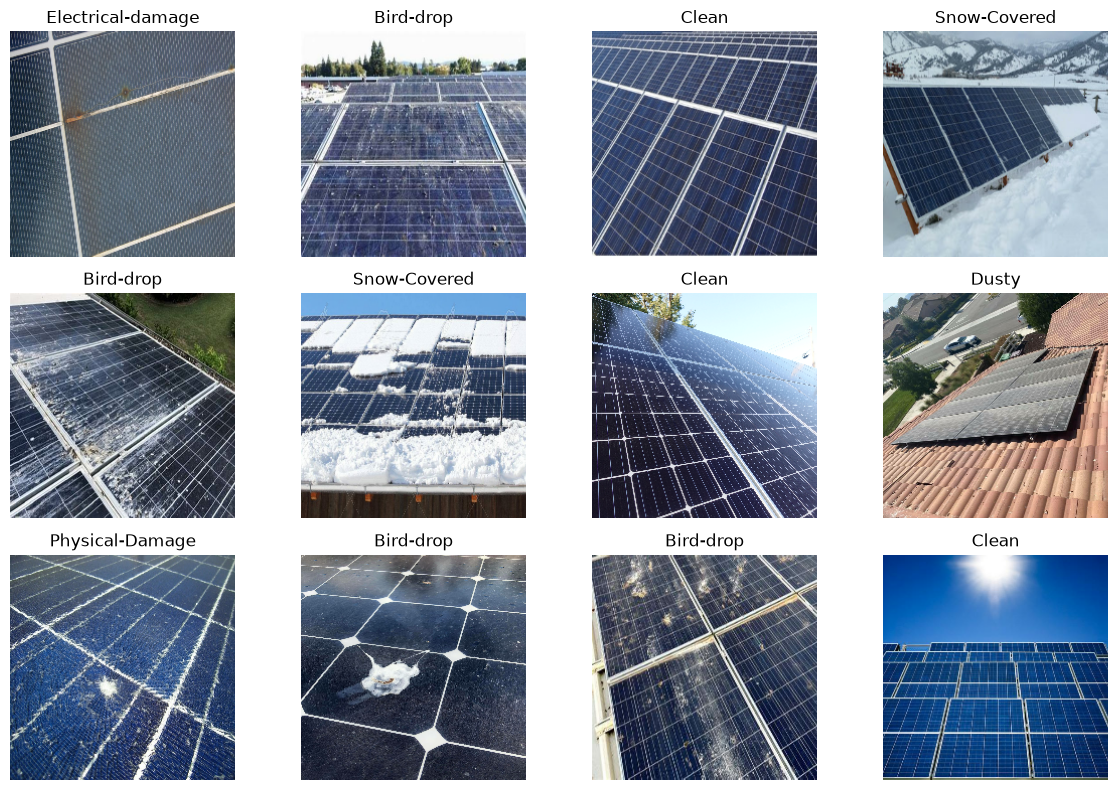

In [32]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):

    for i in range(min(12, len(images))):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[labels[i]]
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(
    buffer_size=AUTOTUNE
)

val_ds = val_ds.prefetch(
    buffer_size=AUTOTUNE
)

test_ds = test_ds.prefetch(
    buffer_size=AUTOTUNE
)

In [34]:
data_augmentation = keras.Sequential([

    layers.RandomFlip(
        "horizontal"
    ),

    layers.RandomRotation(
        0.1
    ),

    layers.RandomZoom(
        0.1
    ),

    layers.RandomContrast(
        0.1
    )

])

print("Data augmentation ready.")

Data augmentation ready.


In [35]:
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

print("MobileNetV2 loaded.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 85s 9us/step
MobileNetV2 loaded.


In [36]:
inputs = keras.Input(
    shape=(224, 224, 3)
)

# Data augmentation
x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Feature extraction
x = base_model(
    x,
    training=False
)

# Convert feature maps into one feature vector
x = layers.GlobalAveragePooling2D()(x)

# Prevent overfitting
x = layers.Dropout(0.3)(x)

# Six-class output
outputs = layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = keras.Model(
    inputs,
    outputs
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [37]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)

print("Model compiled successfully.")

Model compiled successfully.


In [38]:
EPOCHS = 10

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS
)

Epoch 1/10


c:\Users\divye\AppData\Local\Python\pythoncore-3.11-64\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


19/19 ━━━━━━━━━━━━━━━━━━━━ 31s 1s/step - accuracy: 0.2059 - loss: 2.1878 - val_accuracy: 0.1860 - val_loss: 1.8313
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.2323 - loss: 2.0433 - val_accuracy: 0.2403 - val_loss: 1.7622
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2422 - loss: 1.9301 - val_accuracy: 0.2636 - val_loss: 1.6923
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2916 - loss: 1.8279 - val_accuracy: 0.3178 - val_loss: 1.6220
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.3031 - loss: 1.7865 - val_accuracy: 0.3643 - val_loss: 1.5582
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3344 - loss: 1.7319 - val_accuracy: 0.4109 - val_loss: 1.4982
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3262 - loss: 1.6684 - val_accuracy: 0.4264 - val_loss: 1.4466
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3723 - loss: 1.5717 - val_accuracy: 0.4574 - val_loss: 1.3954
Epo

In [39]:
EPOCHS = 10

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS
)

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4580 - loss: 1.4377 - val_accuracy: 0.4806 - val_loss: 1.2741
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4662 - loss: 1.3848 - val_accuracy: 0.4729 - val_loss: 1.2446
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.4695 - loss: 1.3827 - val_accuracy: 0.5116 - val_loss: 1.2208
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5107 - loss: 1.3009 - val_accuracy: 0.4961 - val_loss: 1.1908
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 165s 9s/step - accuracy: 0.4959 - loss: 1.3478 - val_accuracy: 0.5116 - val_loss: 1.1706
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.5272 - loss: 1.2672 - val_accuracy: 0.5271 - val_loss: 1.1422
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.5124 - loss: 1.2401 - val_accuracy: 0.5581 - val_loss: 1.1129
Epoch 8/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.5568 - loss: 1.2253 - val_accuracy: 0.5659 - val_loss

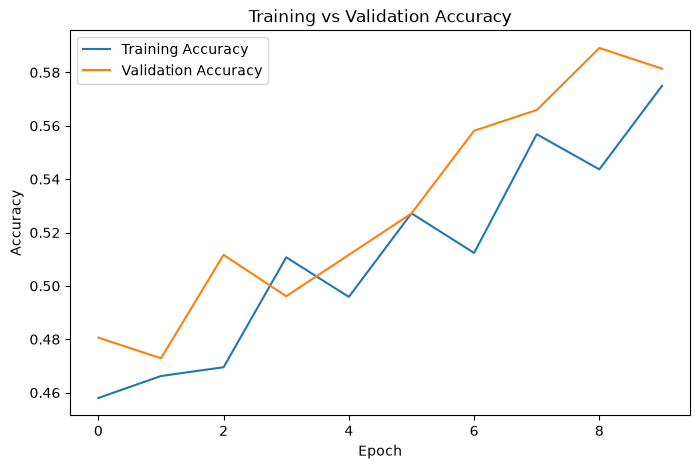

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title(
    "Training vs Validation Accuracy"
)

plt.legend()

plt.show()

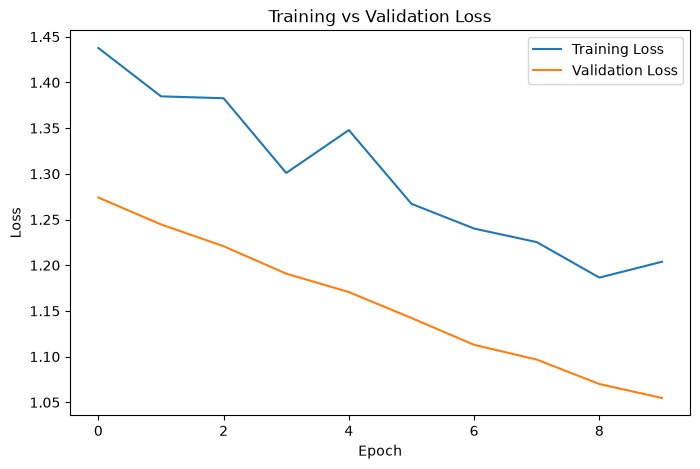

In [41]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Training vs Validation Loss"
)

plt.legend()

plt.show()

In [42]:
test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("Test Loss:", test_loss)

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 667ms/step - accuracy: 0.6617 - loss: 1.0484
Test Loss: 1.0483607053756714
Test Accuracy: 66.17 %


In [43]:
y_true = []

y_pred = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        predicted_classes
    )


print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                   precision    recall  f1-score   support

        Bird-drop       0.51      0.62      0.56        29
            Clean       0.60      0.93      0.73        29
            Dusty       0.66      0.66      0.66        29
Electrical-damage       1.00      0.56      0.72        16
  Physical-Damage       1.00      0.18      0.31        11
     Snow-Covered       1.00      0.68      0.81        19

         accuracy                           0.66       133
        macro avg       0.79      0.61      0.63       133
     weighted avg       0.73      0.66      0.65       133



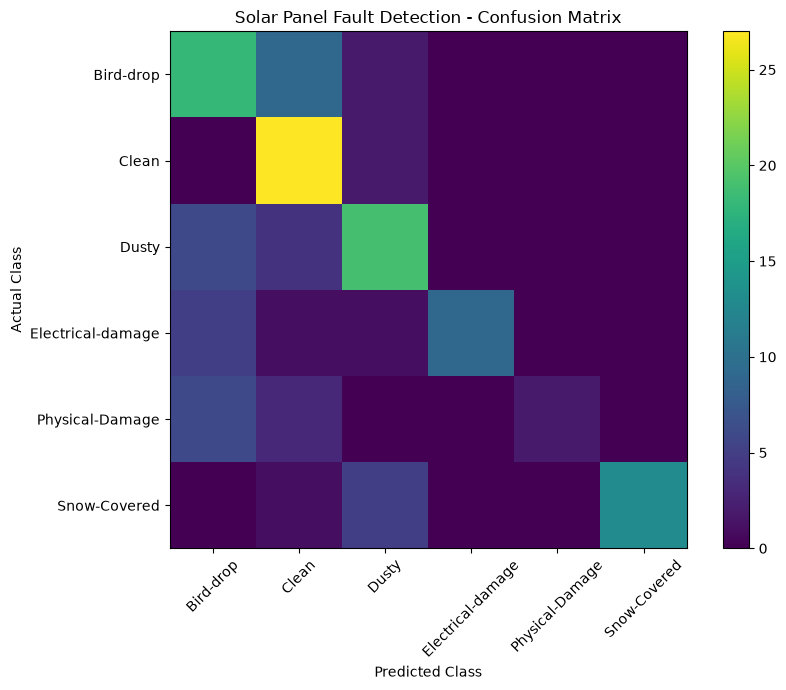

In [44]:
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(9, 7))

plt.imshow(cm)

plt.title(
    "Solar Panel Fault Detection - Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "Actual Class"
)

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.colorbar()

plt.tight_layout()

plt.show()

In [45]:
models_path = "../models"

os.makedirs(
    models_path,
    exist_ok=True
)

model_path = os.path.join(
    models_path,
    "solar_panel_fault_model.keras"
)

model.save(model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
../models\solar_panel_fault_model.keras


In [48]:
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array

image_path = "../images/image2.jpg"

img = load_img(
    image_path,
    target_size=IMG_SIZE
)

img_array = img_to_array(img)

img_array = np.expand_dims(
    img_array,
    axis=0
)

prediction = model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    prediction[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    prediction[0][predicted_index] * 100
)

print("Prediction:", predicted_class)

print(
    "Confidence:",
    round(confidence, 2),
    "%"
)

Prediction: Bird-drop
Confidence: 35.4 %
